In [1]:
import os
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score
)

from tqdm.auto import tqdm



In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cpu


In [ ]:
TRAIN_PATH = "train_for3_2.npz"
TEST_PATH = "test_features_for3_2.npz"

train_data = np.load(TRAIN_PATH, allow_pickle=True)
test_data = np.load(TEST_PATH, allow_pickle=True)

X_train = train_data["images"]

X_test = test_data["images"]

train_ids = train_data["image_id"]

test_ids = test_data["image_id"]

# Метки сохраняем отдельно исключительно
# для независимой оценки после кластеризации.
# В обучение модели они не передаются.

y_reference = train_data["prediction"]

class_names = train_data["label_names"]

NUM_CLUSTERS = 9

print("TRAIN:", X_train.shape)
print("TEST:", X_test.shape)

print("Train IDs:", train_ids.shape)
print("Test IDs:", test_ids.shape)

TRAIN: (3600, 28, 28, 3)
TEST: (900, 28, 28, 3)
Train IDs: (3600,)
Test IDs: (900,)
Number of clusters: 9


In [ ]:
print("Image dtype:", X_train.dtype)

print("Min pixel:", X_train.min())
print("Max pixel:", X_train.max())

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

assert X_train.shape[1:] == (28, 28, 3)
assert X_test.shape[1:] == (28, 28, 3)

assert X_train.dtype == np.uint8
assert X_test.dtype == np.uint8

assert len(X_train) == len(train_ids)
assert len(X_test) == len(test_ids)

assert len(np.unique(train_ids)) == len(train_ids)
assert len(np.unique(test_ids)) == len(test_ids)

assert np.isin(y_reference, np.arange(9)).all()



Image dtype: uint8
Min pixel: 0
Max pixel: 255
Train samples: 3600
Test samples: 900
Data validation completed!


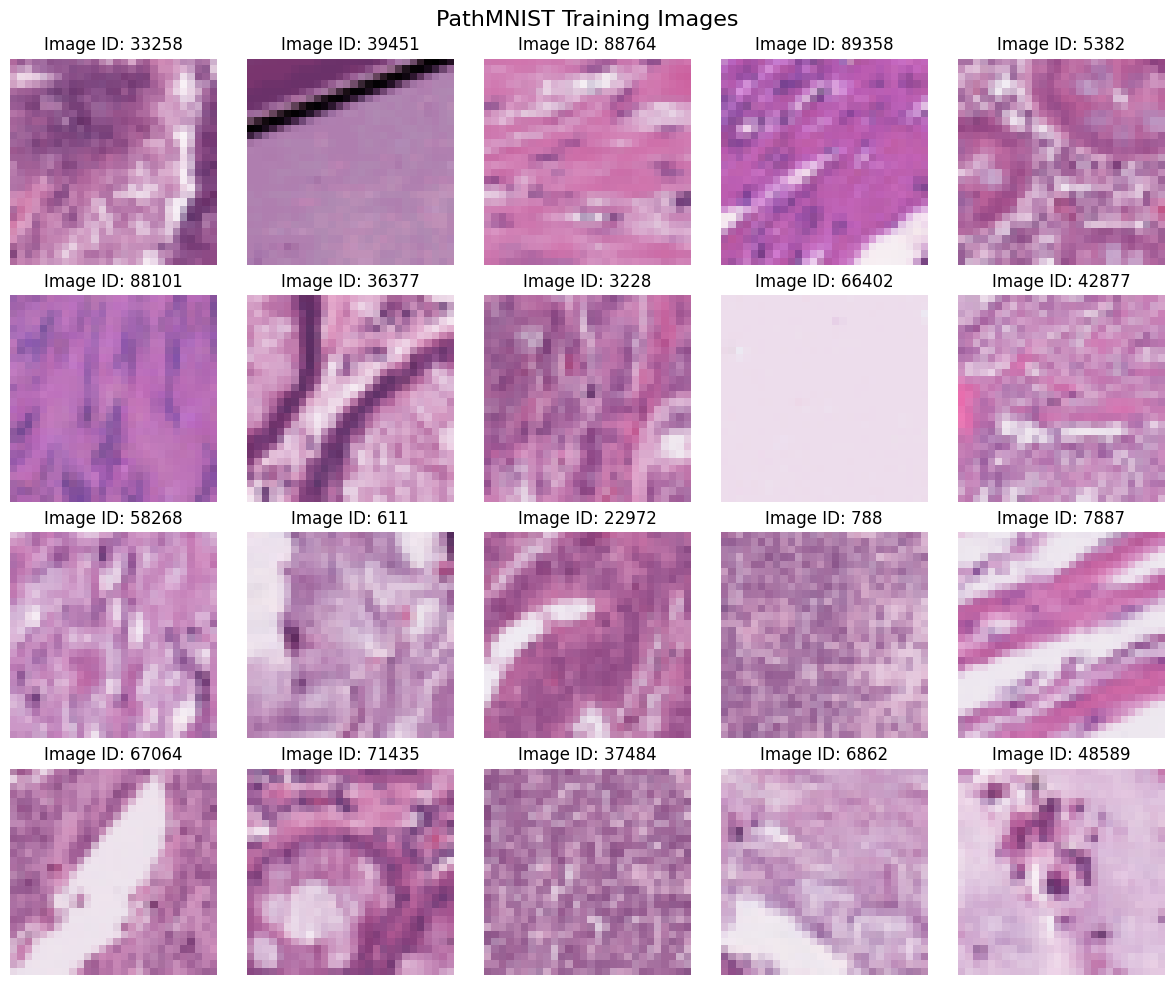

In [5]:
fig, axes = plt.subplots(
    4, 5,
    figsize=(12, 10)
)

indices = np.random.choice(
    len(X_train),
    size=20,
    replace=False
)

for ax, idx in zip(axes.flatten(), indices):

    ax.imshow(X_train[idx])

    ax.set_title(
        f"Image ID: {train_ids[idx]}"
    )

    ax.axis("off")

plt.suptitle(
    "PathMNIST Training Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

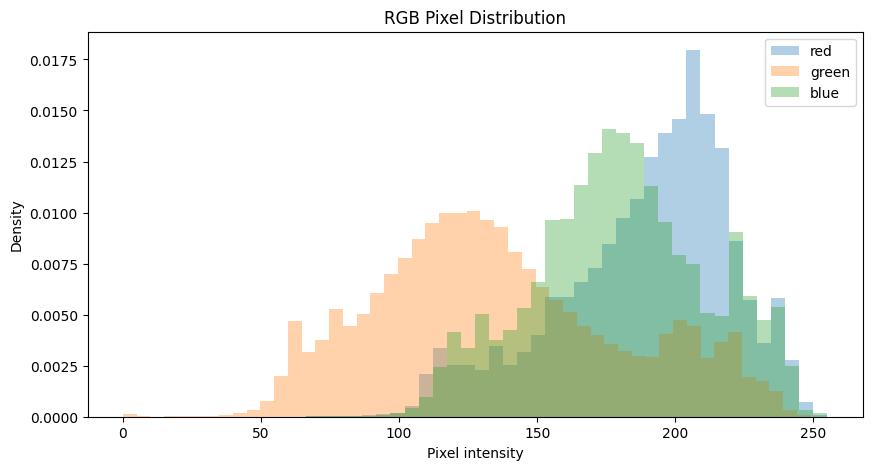

In [6]:
plt.figure(figsize=(10, 5))

for channel, color in enumerate(["red", "green", "blue"]):

    values = X_train[:, :, :, channel].flatten()

    plt.hist(
        values,
        bins=50,
        alpha=0.35,
        density=True,
        label=color
    )

plt.title("RGB Pixel Distribution")

plt.xlabel("Pixel intensity")
plt.ylabel("Density")

plt.legend()
plt.show()

In [7]:
X_train_float = (
    X_train.astype(np.float32) / 255.0
)

X_test_float = (
    X_test.astype(np.float32) / 255.0
)

print("Train range:",
      X_train_float.min(),
      X_train_float.max())

print("Test range:",
      X_test_float.min(),
      X_test_float.max())

Train range: 0.0 1.0
Test range: 0.0 1.0


In [8]:
class HistologyUnsupervisedDataset(Dataset):

    def __init__(self, images, augment=False):

        self.images = images

        self.augment = augment

    def __len__(self):

        return len(self.images)

    def __getitem__(self, idx):

        image = torch.from_numpy(
            self.images[idx].copy()
        )

        image = image.permute(
            2, 0, 1
        ).float()

        if self.augment:

            if random.random() > 0.5:

                image = torch.flip(
                    image,
                    dims=[1]
                )

            if random.random() > 0.5:

                image = torch.flip(
                    image,
                    dims=[2]
                )

            k = random.randint(0, 3)

            image = torch.rot90(
                image,
                k,
                dims=[1, 2]
            )

        return image

In [9]:
BATCH_SIZE = 128

train_dataset = HistologyUnsupervisedDataset(
    X_train_float,
    augment=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Training samples:", len(train_dataset))

print("Training batches:", len(train_loader))

Training samples: 3600
Training batches: 29


In [10]:
class ConvAutoencoder(nn.Module):

    def __init__(self, latent_dim=64):

        super().__init__()

        self.latent_dim = latent_dim

        # Encoder:
        # 28x28 -> 14x14 -> 7x7 -> 4x4

        self.encoder = nn.Sequential(

            nn.Conv2d(
                3, 32,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                64, 128,
                kernel_size=3,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Flatten(),

            nn.Linear(
                128 * 4 * 4,
                256
            ),

            nn.ReLU(inplace=True),

            nn.Linear(
                256,
                latent_dim
            )
        )

        # Decoder

        self.decoder_input = nn.Linear(
            latent_dim,
            128 * 4 * 4
        )

        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                64, 32,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                32, 3,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.Sigmoid()
        )

    def encode(self, x):

        return self.encoder(x)

    def decode(self, z):

        x = self.decoder_input(z)

        x = x.view(
            -1, 128, 4, 4
        )

        x = self.decoder(x)

        x = F.interpolate(
            x,
            size=(28, 28),
            mode="bilinear",
            align_corners=False
        )

        return x

    def forward(self, x):

        z = self.encode(x)

        reconstructed = self.decode(z)

        return reconstructed

In [11]:
LATENT_DIM = 64

autoencoder = ConvAutoencoder(
    latent_dim=LATENT_DIM
).to(DEVICE)

print(autoencoder)

total_params = sum(
    p.numel()
    for p in autoencoder.parameters()
)

print("Total parameters:", total_params)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=2048, out_features=256, bias=True)
    (11): ReLU(inplace=True)
    (12): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder_input): Linear(in_features=64, out_features=2048, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 

In [12]:
AE_EPOCHS = 50

AE_LR = 0.001

criterion = nn.MSELoss()

optimizer = optim.AdamW(
    autoencoder.parameters(),
    lr=AE_LR,
    weight_decay=1e-5
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

ae_history = []

best_loss = float("inf")

best_autoencoder_state = None

PATIENCE = 10

early_stop_counter = 0

In [13]:
for epoch in range(AE_EPOCHS):

    autoencoder.train()

    running_loss = 0.0

    for images in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}"
    ):

        images = images.to(DEVICE)

        # Добавляем небольшой шум

        noisy_images = (
            images +
            0.05 * torch.randn_like(images)
        ).clamp(0, 1)

        optimizer.zero_grad()

        reconstructed = autoencoder(
            noisy_images
        )

        loss = criterion(
            reconstructed,
            images
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

    epoch_loss = (
        running_loss / len(train_dataset)
    )

    ae_history.append(epoch_loss)

    scheduler.step(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{AE_EPOCHS} | "
        f"Reconstruction Loss: {epoch_loss:.6f}"
    )

    if epoch_loss < best_loss:

        best_loss = epoch_loss

        best_autoencoder_state = copy.deepcopy(
            autoencoder.state_dict()
        )

        early_stop_counter = 0

    else:

        early_stop_counter += 1

    if early_stop_counter >= PATIENCE:

        print("Early stopping!")

        break


autoencoder.load_state_dict(
    best_autoencoder_state
)

print("Autoencoder training completed!")
print("Best loss:", best_loss)

Epoch 1:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch 1/50 | Reconstruction Loss: 0.031855


Epoch 2:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch 2/50 | Reconstruction Loss: 0.009984


Epoch 3:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch 3/50 | Reconstruction Loss: 0.009166


... (90 outputs left out)

Epoch 49:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch 49/50 | Reconstruction Loss: 0.004639


Epoch 50:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch 50/50 | Reconstruction Loss: 0.004624
Autoencoder training completed!
Best loss: 0.004623512774705887


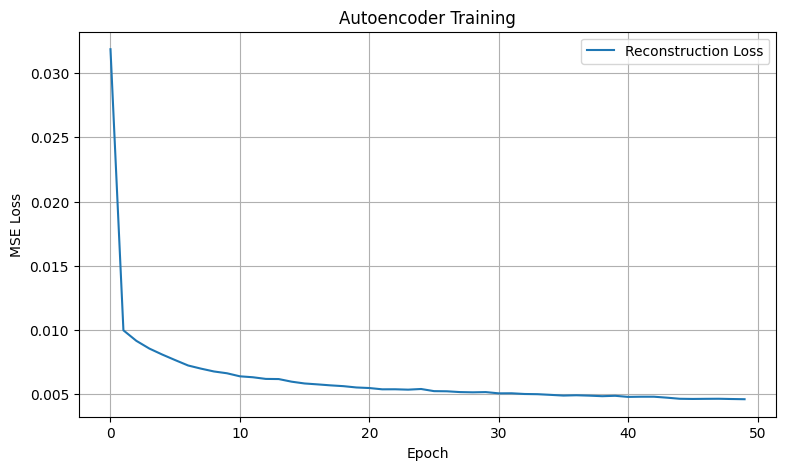

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    ae_history,
    label="Reconstruction Loss"
)

plt.title("Autoencoder Training")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid()

plt.show()

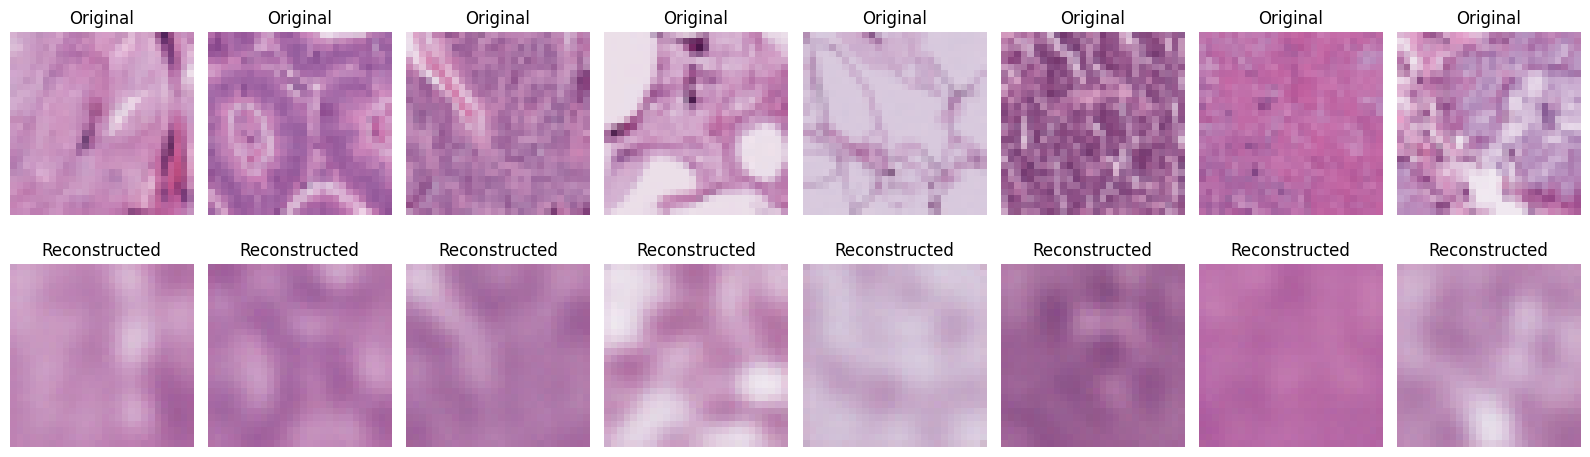

In [15]:
autoencoder.eval()

sample_indices = np.random.choice(
    len(X_train_float),
    size=8,
    replace=False
)

original_images = torch.tensor(
    X_train_float[sample_indices]
).permute(0, 3, 1, 2).float().to(DEVICE)

with torch.no_grad():

    reconstructed_images = autoencoder(
        original_images
    )

fig, axes = plt.subplots(
    2, 8,
    figsize=(16, 5)
)

for i in range(8):

    original = (
        original_images[i]
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    reconstructed = (
        reconstructed_images[i]
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    axes[0, i].imshow(original)
    axes[0, i].set_title("Original")

    axes[1, i].imshow(reconstructed)
    axes[1, i].set_title("Reconstructed")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [16]:
train_embedding_dataset = HistologyUnsupervisedDataset(
    X_train_float,
    augment=False
)

test_embedding_dataset = HistologyUnsupervisedDataset(
    X_test_float,
    augment=False
)

train_embedding_loader = DataLoader(
    train_embedding_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

test_embedding_loader = DataLoader(
    test_embedding_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

In [17]:
def extract_embeddings(model, loader):

    model.eval()

    embeddings = []

    with torch.no_grad():

        for images in tqdm(loader):

            images = images.to(DEVICE)

            latent_vectors = model.encode(
                images
            )

            embeddings.append(
                latent_vectors.cpu().numpy()
            )

    return np.concatenate(
        embeddings,
        axis=0
    )

In [18]:
train_embeddings = extract_embeddings(
    autoencoder,
    train_embedding_loader
)

test_embeddings = extract_embeddings(
    autoencoder,
    test_embedding_loader
)

print("Train embeddings:",
      train_embeddings.shape)

print("Test embeddings:",
      test_embeddings.shape)

assert train_embeddings.shape == (
    len(X_train), LATENT_DIM
)

assert test_embeddings.shape == (
    len(X_test), LATENT_DIM
)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Train embeddings: (3600, 64)
Test embeddings: (900, 64)


In [19]:
scaler = StandardScaler()

train_scaled = scaler.fit_transform(
    train_embeddings
)

test_scaled = scaler.transform(
    test_embeddings
)

print("Train scaled:", train_scaled.shape)
print("Test scaled:", test_scaled.shape)

Train scaled: (3600, 64)
Test scaled: (900, 64)


In [20]:
PCA_COMPONENTS = 32

pca = PCA(
    n_components=PCA_COMPONENTS,
    whiten=True,
    random_state=SEED
)

train_pca = pca.fit_transform(
    train_scaled
)

test_pca = pca.transform(
    test_scaled
)

print("Train PCA:", train_pca.shape)
print("Test PCA:", test_pca.shape)

print(
    "Explained variance:",
    pca.explained_variance_ratio_.sum()
)

Train PCA: (3600, 32)
Test PCA: (900, 32)
Explained variance: 0.9030819


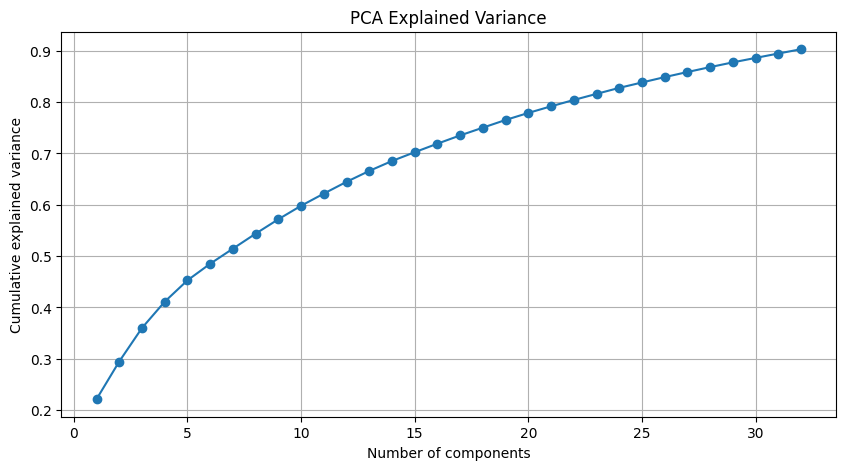

In [21]:
explained_variance = (
    pca.explained_variance_ratio_
)

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, PCA_COMPONENTS + 1),
    np.cumsum(explained_variance),
    marker="o"
)

plt.xlabel("Number of components")

plt.ylabel("Cumulative explained variance")

plt.title("PCA Explained Variance")

plt.grid()

plt.show()

In [22]:
kmeans = KMeans(
    n_clusters=NUM_CLUSTERS,
    init="k-means++",
    n_init=30,
    max_iter=500,
    random_state=SEED
)

In [23]:
train_clusters = kmeans.fit_predict(
    train_pca
)

print("Clustering completed!")

print("Train clusters:",
      train_clusters.shape)

print("Number of clusters:",
      len(np.unique(train_clusters)))

print("Inertia:",
      kmeans.inertia_)

Clustering completed!
Train clusters: (3600,)
Number of clusters: 9
Inertia: 102480.7734375


,cluster,count,percentage
0,0,594,16.500000
1,1,940,26.111111
2,2,353,9.805556
3,3,225,6.250000
4,4,877,24.361111
5,5,3,0.083333
6,6,221,6.138889
7,7,301,8.361111
8,8,86,2.388889


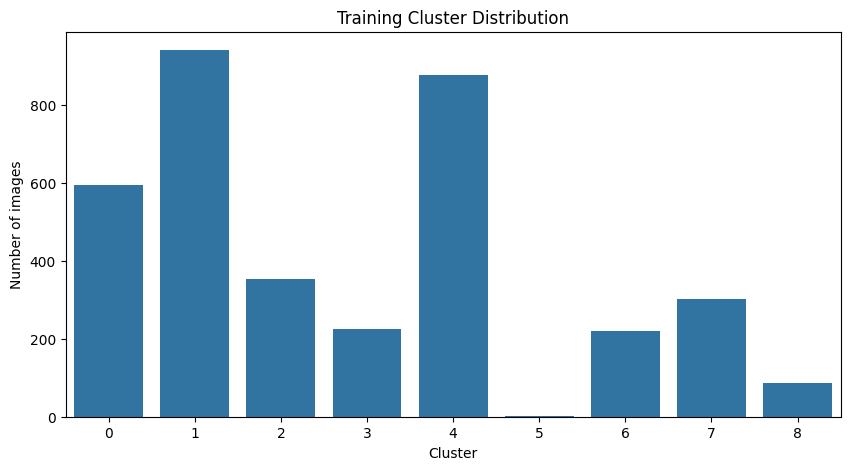

In [24]:
cluster_counts = pd.Series(
    train_clusters
).value_counts().sort_index()

cluster_distribution = pd.DataFrame({

    "cluster": cluster_counts.index,

    "count": cluster_counts.values,

    "percentage": (
        cluster_counts.values /
        len(train_clusters) * 100
    )
})

display(cluster_distribution)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=cluster_distribution,
    x="cluster",
    y="count"
)

plt.title("Training Cluster Distribution")

plt.xlabel("Cluster")
plt.ylabel("Number of images")

plt.show()

In [25]:
silhouette = silhouette_score(
    train_pca,
    train_clusters,
    sample_size=min(1800, len(train_pca)),
    random_state=SEED
)

print("Silhouette Score:", silhouette)

print("KMeans Inertia:", kmeans.inertia_)

Silhouette Score: -0.005573021247982979
KMeans Inertia: 102480.7734375


In [26]:
ari = adjusted_rand_score(
    y_reference,
    train_clusters
)

nmi = normalized_mutual_info_score(
    y_reference,
    train_clusters
)

homogeneity = homogeneity_score(
    y_reference,
    train_clusters
)

completeness = completeness_score(
    y_reference,
    train_clusters
)

evaluation = pd.DataFrame({

    "Metric": [
        "ARI",
        "NMI",
        "Homogeneity",
        "Completeness"
    ],

    "Score": [
        ari,
        nmi,
        homogeneity,
        completeness
    ]

})

display(evaluation)

,Metric,Score
0,ARI,0.178390
1,NMI,0.268449
2,Homogeneity,0.248918
3,Completeness,0.291305


In [27]:
cluster_class_table = pd.crosstab(
    train_clusters,
    y_reference,
    rownames=["Cluster"],
    colnames=["Original Class"]
)

display(cluster_class_table)

Original Class,0,1,2,3,4,5,6,7,8
Cluster,,,,,,,,,
0,327,90,9,9,79,26,38,4,12
1,6,61,50,303,149,66,67,144,94
2,17,2,35,38,33,43,62,24,99
3,13,2,26,18,12,26,47,8,73
4,1,3,252,16,12,266,36,183,108
5,0,0,3,0,0,0,0,0,0
6,0,218,1,0,0,0,0,0,2
7,10,2,34,28,24,45,47,10,101
8,1,3,5,4,11,15,18,3,26


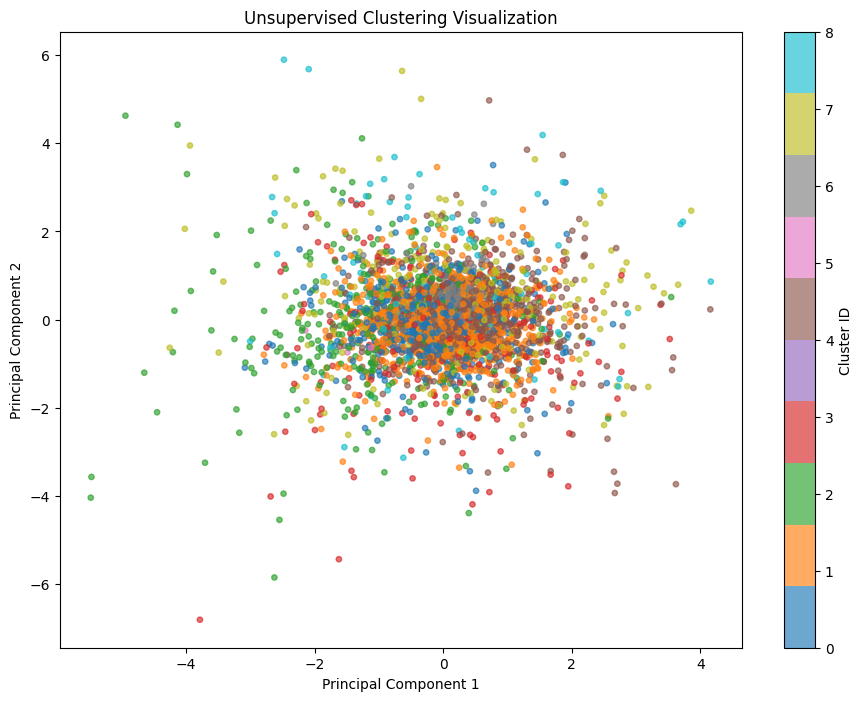

In [28]:
pca_2d = PCA(
    n_components=2,
    random_state=SEED
)

train_2d = pca_2d.fit_transform(
    train_pca
)

plt.figure(figsize=(11, 8))

scatter = plt.scatter(
    train_2d[:, 0],
    train_2d[:, 1],
    c=train_clusters,
    cmap="tab10",
    s=15,
    alpha=0.65
)

plt.title("Unsupervised Clustering Visualization")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    label="Cluster ID"
)

plt.show()

In [29]:
test_clusters = kmeans.predict(
    test_pca
)

test_clusters = test_clusters.astype(
    np.int64
)

print("Test predictions:", test_clusters.shape)

print("Unique clusters:",
      np.unique(test_clusters))

print("Cluster distribution:")

print(
    pd.Series(test_clusters)
    .value_counts()
    .sort_index()
)

Test predictions: (900,)
Unique clusters: [0 1 2 3 4 6 7 8]
Cluster distribution:
0    144
1    256
2     89
3     58
4    199
6     62
7     71
8     21
Name: count, dtype: int64


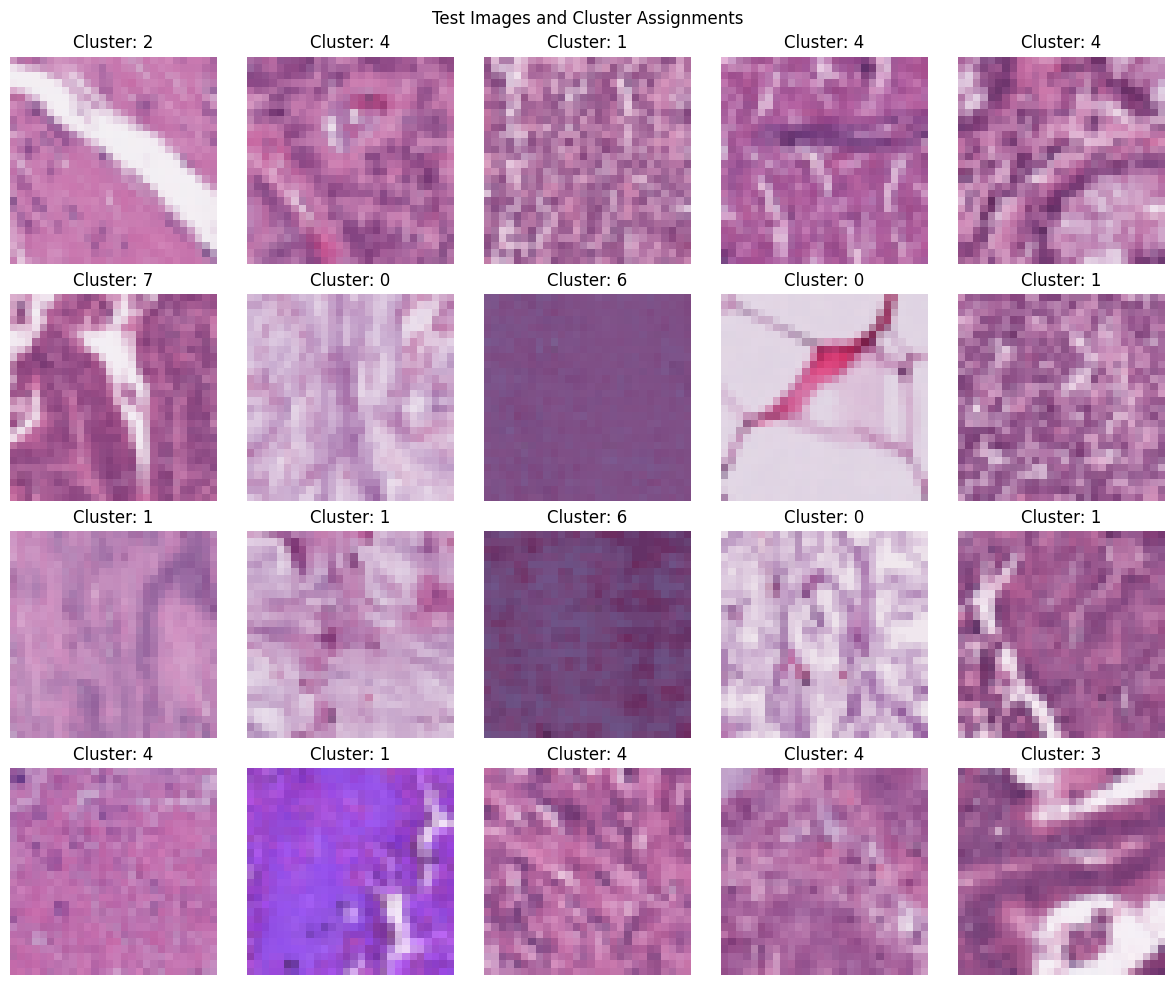

In [30]:
fig, axes = plt.subplots(
    4, 5,
    figsize=(12, 10)
)

indices = np.random.choice(
    len(X_test),
    size=20,
    replace=False
)

for ax, idx in zip(axes.flatten(), indices):

    ax.imshow(X_test[idx])

    ax.set_title(
        f"Cluster: {test_clusters[idx]}"
    )

    ax.axis("off")

plt.suptitle("Test Images and Cluster Assignments")

plt.tight_layout()

plt.show()

In [31]:
output_dir = "outputs"

os.makedirs(
    output_dir,
    exist_ok=True
)

submission = pd.DataFrame({

    "image_id": test_ids,

    "prediction": test_clusters

})

output_path = os.path.join(
    output_dir,
    "task3_2_predictions.csv"
)

submission.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

display(submission.head(10))

Saved: outputs\task3_2_predictions.csv


,image_id,prediction
0,20,4
1,48,0
2,318,1
3,319,1
4,486,0
5,657,7
6,680,2
7,717,1
8,735,0
9,854,0
